# Uber Ride Analytics: NCR 2024
Cleaning, exploring and preparing 150,000 ride bookings for a Power BI dashboard.

## Loading the data and a first look

In [1]:
import pandas as pd
import numpy as np
import os

In [2]:
print(os.getcwd())
print(os.listdir())

C:\Users\ASUS\Uber_Data_Analytics
['.ipynb_checkpoints', 'assets', 'charts', 'dashboards', 'ncr_ride_bookings.csv', 'powerbi_data', 'uber_ride_analysis.ipynb']


In [3]:
df = pd.read_csv("ncr_ride_bookings.csv")
print("Rows and columns:", df.shape)

Rows and columns: (150000, 21)


In [4]:
df.head()

,Date,Time,Booking ID,Booking Status,Customer ID,Vehicle Type,Pickup Location,Drop Location,Avg VTAT,Avg CTAT,...,Reason for cancelling by Customer,Cancelled Rides by Driver,Driver Cancellation Reason,Incomplete Rides,Incomplete Rides Reason,Booking Value,Ride Distance,Driver Ratings,Customer Rating,Payment Method
0,2024-03-23,12:29:38,"""CNR5884300""",No Driver Found,"""CID1982111""",eBike,Palam Vihar,Jhilmil,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-11-29,18:01:39,"""CNR1326809""",Incomplete,"""CID4604802""",Go Sedan,Shastri Nagar,Gurgaon Sector 56,4.9,14.0,...,NaN,NaN,NaN,1.0,Vehicle Breakdown,237.0,5.73,NaN,NaN,UPI
2,2024-08-23,08:56:10,"""CNR8494506""",Completed,"""CID9202816""",Auto,Khandsa,Malviya Nagar,13.4,25.8,...,NaN,NaN,NaN,NaN,NaN,627.0,13.58,4.9,4.9,Debit Card
3,2024-10-21,17:17:25,"""CNR8906825""",Completed,"""CID2610914""",Premier Sedan,Central Secretariat,Inderlok,13.1,28.5,...,NaN,NaN,NaN,NaN,NaN,416.0,34.02,4.6,5.0,UPI
4,2024-09-16,22:08:00,"""CNR1950162""",Completed,"""CID9933542""",Bike,Ghitorni Village,Khan Market,5.3,19.6,...,NaN,NaN,NaN,NaN,NaN,737.0,48.21,4.1,4.3,UPI


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 21 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Date                               150000 non-null  object 
 1   Time                               150000 non-null  object 
 2   Booking ID                         150000 non-null  object 
 3   Booking Status                     150000 non-null  object 
 4   Customer ID                        150000 non-null  object 
 5   Vehicle Type                       150000 non-null  object 
 6   Pickup Location                    150000 non-null  object 
 7   Drop Location                      150000 non-null  object 
 8   Avg VTAT                           139500 non-null  float64
 9   Avg CTAT                           102000 non-null  float64
 10  Cancelled Rides by Customer        10500 non-null   float64
 11  Reason for cancelling by Customer  1050

## Cleaning IDs, dates and repeated booking numbers

In [6]:
clean = df.copy()

In [7]:
for col in ["Booking ID", "Customer ID"]:
    clean[col] = clean[col].str.replace('"', '', regex=False)

clean[["Booking ID", "Customer ID"]].head()

,Booking ID,Customer ID
0,CNR5884300,CID1982111
1,CNR1326809,CID4604802
2,CNR8494506,CID9202816
3,CNR8906825,CID2610914
4,CNR1950162,CID9933542


In [8]:
clean["Date"] = pd.to_datetime(clean["Date"])
clean["Timestamp"] = pd.to_datetime(
    clean["Date"].dt.strftime("%Y-%m-%d") + " " + clean["Time"]
)
clean["Hour"] = clean["Timestamp"].dt.hour

clean[["Date", "Time", "Timestamp", "Hour"]].head()

,Date,Time,Timestamp,Hour
0,2024-03-23,12:29:38,2024-03-23 12:29:38,12
1,2024-11-29,18:01:39,2024-11-29 18:01:39,18
2,2024-08-23,08:56:10,2024-08-23 08:56:10,8
3,2024-10-21,17:17:25,2024-10-21 17:17:25,17
4,2024-09-16,22:08:00,2024-09-16 22:08:00,22


In [9]:
print("First date:", clean["Date"].min().date())
print("Last date:", clean["Date"].max().date())
print("Missing timestamps:", clean["Timestamp"].isna().sum())

First date: 2024-01-01
Last date: 2024-12-30
Missing timestamps: 0


In [10]:
dupes = clean[clean["Booking ID"].duplicated(keep=False)].sort_values("Booking ID")

print("Rows that share a Booking ID:", len(dupes))
print("Fully identical rows:", clean.duplicated().sum())

dupes[["Booking ID", "Date", "Customer ID", "Booking Status", "Vehicle Type"]].head(6)

Rows that share a Booking ID: 2457
Fully identical rows: 0


,Booking ID,Date,Customer ID,Booking Status,Vehicle Type
81334,CNR1026036,2024-10-15,CID6480133,Completed,Go Mini
9192,CNR1026036,2024-07-21,CID6974869,No Driver Found,Go Mini
9587,CNR1029172,2024-12-17,CID6382731,Completed,Auto
1353,CNR1029172,2024-01-19,CID2615731,Incomplete,Bike
82029,CNR1051228,2024-11-05,CID3177617,Completed,Auto
110412,CNR1051228,2024-01-31,CID5242056,Completed,Premier Sedan


## Building analysis columns for time, status and revenue


In [11]:
clean["RideKey"] = "R" + (clean.index + 1).astype(str).str.zfill(6)

clean["RideKey"].head()

0    R000001
1    R000002
2    R000003
3    R000004
4    R000005
Name: RideKey, dtype: object

In [12]:
clean["MonthNum"] = clean["Timestamp"].dt.month
clean["MonthName"] = clean["Timestamp"].dt.month_name()
clean["Quarter"] = "Q" + clean["Timestamp"].dt.quarter.astype(str)
clean["WeekdayNum"] = clean["Timestamp"].dt.dayofweek
clean["WeekdayName"] = clean["Timestamp"].dt.day_name()
clean["IsWeekend"] = (clean["WeekdayNum"] >= 5).astype(int)

In [13]:
clean["TimeSlot"] = pd.cut(
    clean["Hour"],
    bins=[-1, 4, 8, 11, 14, 20, 23],
    labels=["Late Night", "Early Morning", "Morning Peak", "Midday", "Evening Peak", "Night"],
)

clean[["RideKey", "Timestamp", "MonthName", "Quarter", "WeekdayName", "IsWeekend", "TimeSlot"]].head()

,RideKey,Timestamp,MonthName,Quarter,WeekdayName,IsWeekend,TimeSlot
0,R000001,2024-03-23 12:29:38,March,Q1,Saturday,1,Midday
1,R000002,2024-11-29 18:01:39,November,Q4,Friday,0,Evening Peak
2,R000003,2024-08-23 08:56:10,August,Q3,Friday,0,Early Morning
3,R000004,2024-10-21 17:17:25,October,Q4,Monday,0,Evening Peak
4,R000005,2024-09-16 22:08:00,September,Q3,Monday,0,Night


In [14]:
print("RideKey all unique:", clean["RideKey"].is_unique)
print()
print(clean["TimeSlot"].value_counts().sort_index())

RideKey all unique: True

TimeSlot
Late Night        6776
Early Morning    19257
Morning Peak     26201
Midday           19507
Evening Peak     61953
Night            16306
Name: count, dtype: int64


In [15]:
clean["IsCompleted"] = (clean["Booking Status"] == "Completed").astype(int)
clean["IsCancelledByCustomer"] = (clean["Booking Status"] == "Cancelled by Customer").astype(int)
clean["IsCancelledByDriver"] = (clean["Booking Status"] == "Cancelled by Driver").astype(int)
clean["IsNoDriverFound"] = (clean["Booking Status"] == "No Driver Found").astype(int)
clean["IsIncomplete"] = (clean["Booking Status"] == "Incomplete").astype(int)

In [16]:
flag_cols = ["IsCompleted", "IsCancelledByCustomer", "IsCancelledByDriver", "IsNoDriverFound", "IsIncomplete"]

print(clean[flag_cols].sum())
print()
print("Flags per ride:", clean[flag_cols].sum(axis=1).value_counts().to_dict())

IsCompleted              93000
IsCancelledByCustomer    10500
IsCancelledByDriver      27000
IsNoDriverFound          10500
IsIncomplete              9000
dtype: int64

Flags per ride: {1: 150000}


In [17]:
clean["CompletedRevenue"] = np.where(clean["IsCompleted"] == 1, clean["Booking Value"], 0)
clean["IncompleteValue"] = np.where(clean["IsIncomplete"] == 1, clean["Booking Value"], 0)

clean[["Booking Status", "Booking Value", "CompletedRevenue", "IncompleteValue"]].head(6)

,Booking Status,Booking Value,CompletedRevenue,IncompleteValue
0,No Driver Found,NaN,0.0,0.0
1,Incomplete,237.0,0.0,237.0
2,Completed,627.0,627.0,0.0
3,Completed,416.0,416.0,0.0
4,Completed,737.0,737.0,0.0
5,Completed,316.0,316.0,0.0


In [18]:
print("Completed revenue: ₹{:,.0f}".format(clean["CompletedRevenue"].sum()))
print("Incomplete ride value: ₹{:,.0f}".format(clean["IncompleteValue"].sum()))
print("Table shape:", clean.shape)

Completed revenue: ₹47,260,574
Incomplete ride value: ₹4,585,609
Table shape: (150000, 38)


## Checking the headline numbers

In [19]:
total_bookings = len(clean)
completed_rides = clean[clean["IsCompleted"] == 1]
cancelled = clean["IsCancelledByCustomer"].sum() + clean["IsCancelledByDriver"].sum()

print("Total bookings:", f"{total_bookings:,}")
print("Completed rides:", f"{len(completed_rides):,}")
print("Completion rate:", f"{len(completed_rides) / total_bookings * 100:.1f}%")
print("Cancellation rate:", f"{cancelled / total_bookings * 100:.1f}%")
print("Revenue (completed only): ₹" + f"{clean['CompletedRevenue'].sum():,.0f}")
print("Average fare: ₹" + f"{completed_rides['Booking Value'].mean():.2f}")
print("Average distance:", f"{completed_rides['Ride Distance'].mean():.2f}", "km")
print("Total distance:", f"{completed_rides['Ride Distance'].sum():,.0f}", "km")
print("Revenue per km: ₹" + f"{completed_rides['Booking Value'].sum() / completed_rides['Ride Distance'].sum():.2f}")
print("Average customer rating:", f"{completed_rides['Customer Rating'].mean():.2f}")
print("Average driver rating:", f"{completed_rides['Driver Ratings'].mean():.2f}")

Total bookings: 150,000
Completed rides: 93,000
Completion rate: 62.0%
Cancellation rate: 25.0%
Revenue (completed only): ₹47,260,574
Average fare: ₹508.18
Average distance: 26.00 km
Total distance: 2,418,046 km
Revenue per km: ₹19.54
Average customer rating: 4.40
Average driver rating: 4.23


In [20]:
status = clean["Booking Status"].value_counts().rename("Rides").to_frame()
status["Share %"] = (status["Rides"] / total_bookings * 100).round(1)
status

,Rides,Share %
Booking Status,,
Completed,93000,62.0
Cancelled by Driver,27000,18.0
No Driver Found,10500,7.0
Cancelled by Customer,10500,7.0
Incomplete,9000,6.0


In [21]:
vehicle = clean.groupby("Vehicle Type").agg(
    Bookings=("RideKey", "count"),
    Completed=("IsCompleted", "sum"),
    Revenue=("CompletedRevenue", "sum"),
)

vehicle["CompletionRate %"] = (vehicle["Completed"] / vehicle["Bookings"] * 100).round(1)
vehicle["Revenue Share %"] = (vehicle["Revenue"] / vehicle["Revenue"].sum() * 100).round(1)
vehicle = vehicle.sort_values("Revenue", ascending=False)
vehicle

,Bookings,Completed,Revenue,CompletionRate %,Revenue Share %
Vehicle Type,,,,,
Auto,37419,23155,11727615.0,61.9,24.8
Go Mini,29806,18549,9411418.0,62.2,19.9
Go Sedan,27141,16676,8538560.0,61.4,18.1
Bike,22517,14034,7144913.0,62.3,15.1
Premier Sedan,18111,11252,5733655.0,62.1,12.1
eBike,10557,6551,3298157.0,62.1,7.0
Uber XL,4449,2783,1406256.0,62.6,3.0


## Exploring demand patterns and customer behaviour

In [22]:
hourly = clean.groupby("Hour").size().rename("Rides")

print("Busiest hours:")
print(hourly.sort_values(ascending=False).head(5))
print()
print("Quietest hours:")
print(hourly.sort_values().head(3))

Busiest hours:
Hour
18    12397
19    11047
17    11044
16     9633
20     9630
Name: Rides, dtype: int64

Quietest hours:
Hour
4    1321
2    1339
1    1360
Name: Rides, dtype: int64


In [23]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

heat = clean.pivot_table(
    index="Hour",
    columns="WeekdayName",
    values="RideKey",
    aggfunc="count",
)[weekday_order]

heat.loc[[3, 8, 10, 18]]

WeekdayName,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
Hour,,,,,,,
3,203,206,180,197,203,190,204
8,1026,1026,942,937,984,965,981
10,1335,1391,1326,1338,1374,1408,1405
18,1835,1763,1789,1687,1767,1800,1756


In [24]:
payment = (
    clean[clean["IsCompleted"] == 1]
    .groupby("Payment Method")
    .agg(Rides=("RideKey", "count"), Revenue=("CompletedRevenue", "sum"))
    .sort_values("Revenue", ascending=False)
)

payment["Revenue Share %"] = (payment["Revenue"] / payment["Revenue"].sum() * 100).round(1)
payment

,Rides,Revenue,Revenue Share %
Payment Method,,,
UPI,41834,21274591.0,45.0
Cash,23114,11756071.0,24.9
Uber Wallet,11206,5669070.0,12.0
Credit Card,9320,4753767.0,10.1
Debit Card,7526,3807075.0,8.1


In [25]:
print(clean["Reason for cancelling by Customer"].value_counts())
print()
print(clean["Driver Cancellation Reason"].value_counts())
print()
print(clean["Incomplete Rides Reason"].value_counts())

Reason for cancelling by Customer
Wrong Address                                   2362
Change of plans                                 2353
Driver is not moving towards pickup location    2335
Driver asked to cancel                          2295
AC is not working                               1155
Name: count, dtype: int64

Driver Cancellation Reason
Customer related issue                 6837
The customer was coughing/sick         6751
Personal & Car related issues          6726
More than permitted people in there    6686
Name: count, dtype: int64

Incomplete Rides Reason
Customer Demand      3040
Vehicle Breakdown    3012
Other Issue          2948
Name: count, dtype: int64


In [26]:
pickups = clean["Pickup Location"].value_counts()

print("Top 5 pickups:")
print(pickups.head(5))
print()
print("Number of pickup locations:", len(pickups))
print("Busiest vs quietest pickup:", pickups.max(), "vs", pickups.min())

routes = (clean["Pickup Location"] + " to " + clean["Drop Location"]).value_counts()
print("Distinct routes:", len(routes), "| most repeated route:", routes.max(), "rides")

Top 5 pickups:
Pickup Location
Khandsa            949
Barakhamba Road    946
Saket              931
Badarpur           921
Pragati Maidan     920
Name: count, dtype: int64

Number of pickup locations: 176
Busiest vs quietest pickup: 949 vs 790
Distinct routes: 30564 | most repeated route: 17 rides


## Exporting clean tables for Power BI

In [27]:
clean["DistanceBand"] = pd.cut(
    clean["Ride Distance"],
    bins=[0, 10, 20, 30, 40, 100],
    labels=["0-10 km", "10-20 km", "20-30 km", "30-40 km", "40+ km"],
)

clean["DistanceBand"].value_counts().sort_index()

DistanceBand
0-10 km     19766
10-20 km    23978
20-30 km    19508
30-40 km    19500
40+ km      19248
Name: count, dtype: int64

In [28]:
rides = clean.rename(columns={
    "Booking ID": "BookingID",
    "Customer ID": "CustomerID",
    "Vehicle Type": "VehicleType",
    "Pickup Location": "PickupLocation",
    "Drop Location": "DropLocation",
    "Booking Status": "BookingStatus",
    "Payment Method": "PaymentMethod",
    "Booking Value": "BookingValue",
    "Ride Distance": "RideDistance",
    "Driver Ratings": "DriverRating",
    "Customer Rating": "CustomerRating",
    "Avg VTAT": "AvgVTAT",
    "Avg CTAT": "AvgCTAT",
    "Reason for cancelling by Customer": "CustomerCancelReason",
    "Driver Cancellation Reason": "DriverCancelReason",
    "Incomplete Rides Reason": "IncompleteReason",
})[[
    "RideKey", "BookingID", "CustomerID", "Date", "Hour",
    "VehicleType", "PickupLocation", "DropLocation",
    "BookingStatus", "PaymentMethod",
    "IsCompleted", "IsCancelledByCustomer", "IsCancelledByDriver", "IsNoDriverFound", "IsIncomplete",
    "BookingValue", "CompletedRevenue", "IncompleteValue",
    "RideDistance", "DistanceBand", "AvgVTAT", "AvgCTAT",
    "DriverRating", "CustomerRating",
    "CustomerCancelReason", "DriverCancelReason", "IncompleteReason",
]]

print(rides.shape)

(150000, 27)


In [29]:
dates = pd.DataFrame({"Date": pd.date_range("2024-01-01", "2024-12-31")})

dates["Year"] = dates["Date"].dt.year
dates["MonthNum"] = dates["Date"].dt.month
dates["MonthName"] = dates["Date"].dt.month_name()
dates["MonthShort"] = dates["Date"].dt.strftime("%b")
dates["Quarter"] = "Q" + dates["Date"].dt.quarter.astype(str)
dates["WeekdayNum"] = dates["Date"].dt.dayofweek
dates["WeekdayName"] = dates["Date"].dt.day_name()
dates["WeekdayShort"] = dates["Date"].dt.strftime("%a")
dates["IsWeekend"] = (dates["WeekdayNum"] >= 5).astype(int)
dates["DayOfMonth"] = dates["Date"].dt.day

print(dates.shape)
dates.head(3)

(366, 11)


,Date,Year,MonthNum,MonthName,MonthShort,Quarter,WeekdayNum,WeekdayName,WeekdayShort,IsWeekend,DayOfMonth
0,2024-01-01,2024,1,January,Jan,Q1,0,Monday,Mon,0,1
1,2024-01-02,2024,1,January,Jan,Q1,1,Tuesday,Tue,0,2
2,2024-01-03,2024,1,January,Jan,Q1,2,Wednesday,Wed,0,3


In [30]:
hours = pd.DataFrame({"Hour": range(24)})
hours["HourLabel"] = hours["Hour"].astype(str).str.zfill(2) + ":00"

time_bins = [-1, 4, 8, 11, 14, 20, 23]
hours["TimeSlot"] = pd.cut(
    hours["Hour"], bins=time_bins,
    labels=["Late Night", "Early Morning", "Morning Peak", "Midday", "Evening Peak", "Night"],
).astype(str)
hours["TimeSlotOrder"] = pd.cut(hours["Hour"], bins=time_bins, labels=[1, 2, 3, 4, 5, 6]).astype(int)

hours.iloc[[0, 5, 9, 12, 15, 21]]

,Hour,HourLabel,TimeSlot,TimeSlotOrder
0,0,00:00,Late Night,1
5,5,05:00,Early Morning,2
9,9,09:00,Morning Peak,3
12,12,12:00,Midday,4
15,15,15:00,Evening Peak,5
21,21,21:00,Night,6


In [31]:
vehicle_dim = pd.DataFrame({
    "VehicleType": ["Auto", "Bike", "eBike", "Go Mini", "Go Sedan", "Premier Sedan", "Uber XL"],
    "VehicleCategory": ["Three-wheeler", "Two-wheeler", "Two-wheeler", "Car", "Car", "Car", "Car"],
})

print("Vehicle types match:", set(rides["VehicleType"]) == set(vehicle_dim["VehicleType"]))

Vehicle types match: True


In [32]:
os.makedirs("powerbi_data", exist_ok=True)

rides.to_csv("powerbi_data/rides.csv", index=False)
dates.to_csv("powerbi_data/dim_date.csv", index=False)
hours.to_csv("powerbi_data/dim_time.csv", index=False)
vehicle_dim.to_csv("powerbi_data/dim_vehicle.csv", index=False)

print(os.listdir("powerbi_data"))

['dim_date.csv', 'dim_time.csv', 'dim_vehicle.csv', 'rides.csv']


In [33]:
check = pd.read_csv("powerbi_data/rides.csv")

print("Shape:", check.shape)
print("Completed revenue:", check["CompletedRevenue"].sum())
print("First date:", check["Date"].iloc[0])
print("RideKey unique:", check["RideKey"].is_unique)

Shape: (150000, 27)
Completed revenue: 47260574.0
First date: 2024-03-23
RideKey unique: True


## Auditing data quality

In [34]:
completed = clean[clean["Booking Status"] == "Completed"]
status = clean["Booking Status"]

print("Customer rating range:", completed["Customer Rating"].min(), "to", completed["Customer Rating"].max())
print("Driver rating range:", completed["Driver Ratings"].min(), "to", completed["Driver Ratings"].max())
print("Fare range: ₹" + str(clean["Booking Value"].min()), "to ₹" + str(clean["Booking Value"].max()))
print("Distance range:", clean["Ride Distance"].min(), "to", clean["Ride Distance"].max(), "km")
print("VTAT range:", clean["Avg VTAT"].min(), "to", clean["Avg VTAT"].max())
print("CTAT range:", clean["Avg CTAT"].min(), "to", clean["Avg CTAT"].max())
print()
print("Completed rides missing a fare:", completed["Booking Value"].isna().sum())
print("Completed rides missing a rating:", completed["Customer Rating"].isna().sum())
print("Completed rides missing a payment method:", completed["Payment Method"].isna().sum())
print("Cancelled or no-driver rides that have a fare:",
      clean[~status.isin(["Completed", "Incomplete"])]["Booking Value"].notna().sum())
print("Rides where pickup equals drop:", (clean["Pickup Location"] == clean["Drop Location"]).sum())
print()
print("Customer-cancel marker matches status:", (clean["Cancelled Rides by Customer"].notna() == (status == "Cancelled by Customer")).all())
print("Driver-cancel marker matches status:", (clean["Cancelled Rides by Driver"].notna() == (status == "Cancelled by Driver")).all())
print("Incomplete marker matches status:", (clean["Incomplete Rides"].notna() == (status == "Incomplete")).all())

Customer rating range: 3.0 to 5.0
Driver rating range: 3.0 to 5.0
Fare range: ₹50.0 to ₹4277.0
Distance range: 1.0 to 50.0 km
VTAT range: 2.0 to 20.0
CTAT range: 10.0 to 45.0

Completed rides missing a fare: 0
Completed rides missing a rating: 0
Completed rides missing a payment method: 0
Cancelled or no-driver rides that have a fare: 0
Rides where pickup equals drop: 0

Customer-cancel marker matches status: True
Driver-cancel marker matches status: True
Incomplete marker matches status: True


In [35]:
text_cols = ["Booking Status", "Vehicle Type", "Pickup Location", "Drop Location", "Payment Method"]

for col in text_cols:
    values = clean[col].dropna()
    print(col, "- values with stray spaces:", (values != values.str.strip()).sum())

Booking Status - values with stray spaces: 0
Vehicle Type - values with stray spaces: 0
Pickup Location - values with stray spaces: 0
Drop Location - values with stray spaces: 0
Payment Method - values with stray spaces: 0


In [36]:
q1 = completed["Booking Value"].quantile(0.25)
q3 = completed["Booking Value"].quantile(0.75)
upper_limit = q3 + 1.5 * (q3 - q1)

print("Fares above the usual range (over ₹" + f"{upper_limit:,.2f}" + "):",
      f"{(completed['Booking Value'] > upper_limit).sum():,}")
print("Correlation between fare and distance:",
      round(completed["Booking Value"].corr(completed["Ride Distance"]), 3))

Fares above the usual range (over ₹1,371.50): 3,127
Correlation between fare and distance: 0.006


## Comparing vehicles, payments, cancellations, fares and ratings

In [37]:
quality = completed.groupby("Vehicle Type").agg(
    AvgFare=("Booking Value", "mean"),
    AvgDistanceKm=("Ride Distance", "mean"),
    CustomerRating=("Customer Rating", "mean"),
    DriverRating=("Driver Ratings", "mean"),
    VTAT=("Avg VTAT", "mean"),
    CTAT=("Avg CTAT", "mean"),
).round(2)

vehicle_profile = vehicle[["Bookings", "CompletionRate %"]].join(quality)
vehicle_profile

,Bookings,CompletionRate %,AvgFare,AvgDistanceKm,CustomerRating,DriverRating,VTAT,CTAT
Vehicle Type,,,,,,,,
Auto,37419,61.9,506.48,25.99,4.40,4.23,8.49,30.03
Go Mini,29806,62.2,507.38,25.99,4.40,4.23,8.52,30.05
Go Sedan,27141,61.4,512.03,25.98,4.41,4.23,8.49,29.95
Bike,22517,62.3,509.11,26.00,4.40,4.23,8.57,30.07
Premier Sedan,18111,62.1,509.57,25.95,4.40,4.23,8.47,30.09
eBike,10557,62.1,503.46,26.34,4.40,4.23,8.54,30.05
Uber XL,4449,62.6,505.30,25.72,4.40,4.24,8.59,30.07


In [38]:
vehicle_profile.drop(columns="Bookings").agg(["min", "max"]).round(2)

,CompletionRate %,AvgFare,AvgDistanceKm,CustomerRating,DriverRating,VTAT,CTAT
min,61.4,503.46,25.72,4.40,4.23,8.47,29.95
max,62.6,512.03,26.34,4.41,4.24,8.59,30.09


In [39]:
import os
import calendar
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("charts", exist_ok=True)

BLACK = "#000000"
GREY = "#545454"
LIGHT = "#AFAFAF"
BLUE = "#276EF1"
RED = "#E11900"
GREEN = "#05A357"

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#E2E2E2",
    "axes.axisbelow": True,
    "font.size": 11,
})

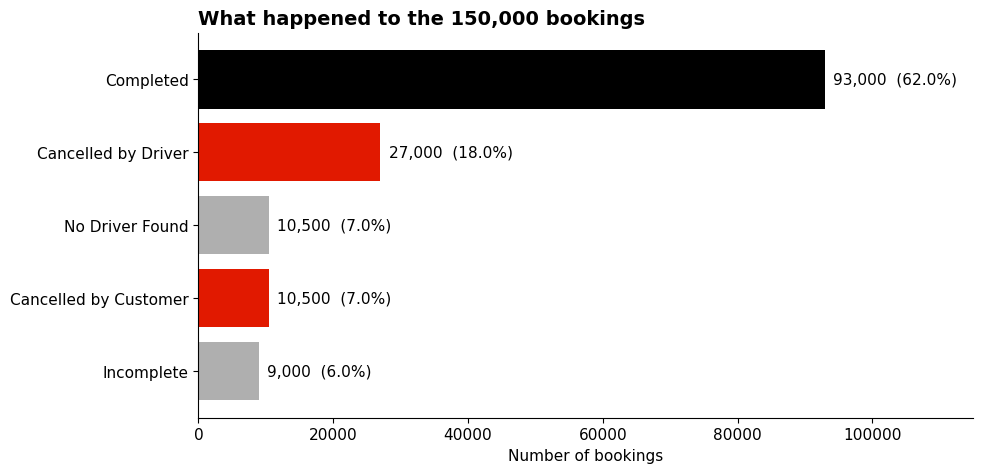

In [40]:
# Chart 01: what happened to every booking
status_counts = clean["Booking Status"].value_counts()

colors = [
    BLACK if s == "Completed" else RED if s.startswith("Cancelled") else LIGHT
    for s in status_counts.index
]

fig, ax = plt.subplots()
bars = ax.barh(status_counts.index[::-1], status_counts.values[::-1], color=colors[::-1])

for bar, value in zip(bars, status_counts.values[::-1]):
    ax.text(value + 1200, bar.get_y() + bar.get_height() / 2,
            f"{value:,}  ({value / len(clean):.1%})", va="center")

ax.set_title("What happened to the 150,000 bookings")
ax.set_xlabel("Number of bookings")
ax.set_xlim(0, 115000)
ax.grid(False)

fig.savefig("charts/01_booking_outcomes.png", dpi=200, bbox_inches="tight")
plt.show()

In [41]:

monthly = clean.groupby("MonthNum").agg(
    Bookings=("RideKey", "count"),
    Completed=("IsCompleted", "sum"),
    Revenue=("CompletedRevenue", "sum"),
)

monthly["DaysInData"] = clean.groupby("MonthNum")["Date"].nunique()
monthly["BookingsPerDay"] = (monthly["Bookings"] / monthly["DaysInData"]).round(0)
monthly["CompletionRate %"] = (monthly["Completed"] / monthly["Bookings"] * 100).round(1)
monthly["AvgFare"] = (monthly["Revenue"] / monthly["Completed"]).round(2)
monthly["Revenue MoM %"] = (monthly["Revenue"].pct_change() * 100).round(1)

monthly.index = monthly.index.map(lambda m: calendar.month_abbr[m])
monthly.index.name = "Month"

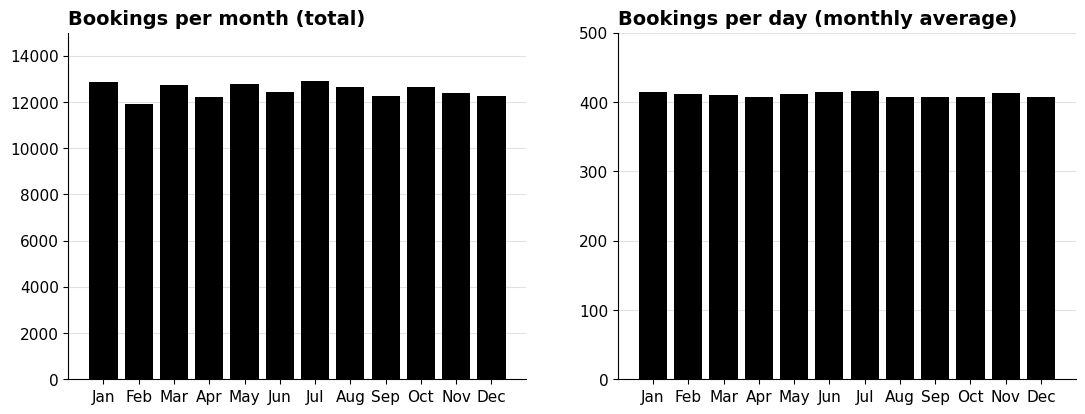

In [42]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(monthly.index, monthly["Bookings"], color=BLACK)
axes[0].set_title("Bookings per month (total)")
axes[0].set_ylim(0, 15000)

axes[1].bar(monthly.index, monthly["BookingsPerDay"], color=BLACK)
axes[1].set_title("Bookings per day (monthly average)")
axes[1].set_ylim(0, 500)

fig.savefig("charts/02_monthly_bookings.png", dpi=200, bbox_inches="tight")
plt.show()

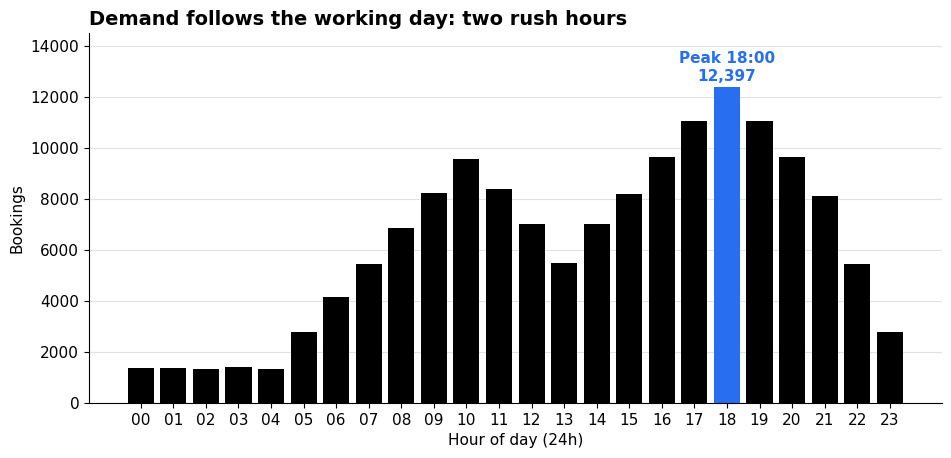

In [43]:
# Chart 03: demand by hour of the day
hourly = clean.groupby("Hour").size()

colors = [BLUE if h == hourly.idxmax() else BLACK for h in hourly.index]

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.bar(hourly.index, hourly.values, color=colors)
ax.set_xticks(range(24))
ax.set_xticklabels([f"{h:02d}" for h in range(24)])
ax.text(hourly.idxmax(), hourly.max() + 250,
        f"Peak {hourly.idxmax()}:00\n{hourly.max():,}",
        ha="center", color=BLUE, fontweight="bold")
ax.set_title("Demand follows the working day: two rush hours")
ax.set_xlabel("Hour of day (24h)")
ax.set_ylabel("Bookings")
ax.set_ylim(0, 14500)

fig.savefig("charts/03_hourly_demand.png", dpi=200, bbox_inches="tight")
plt.show()

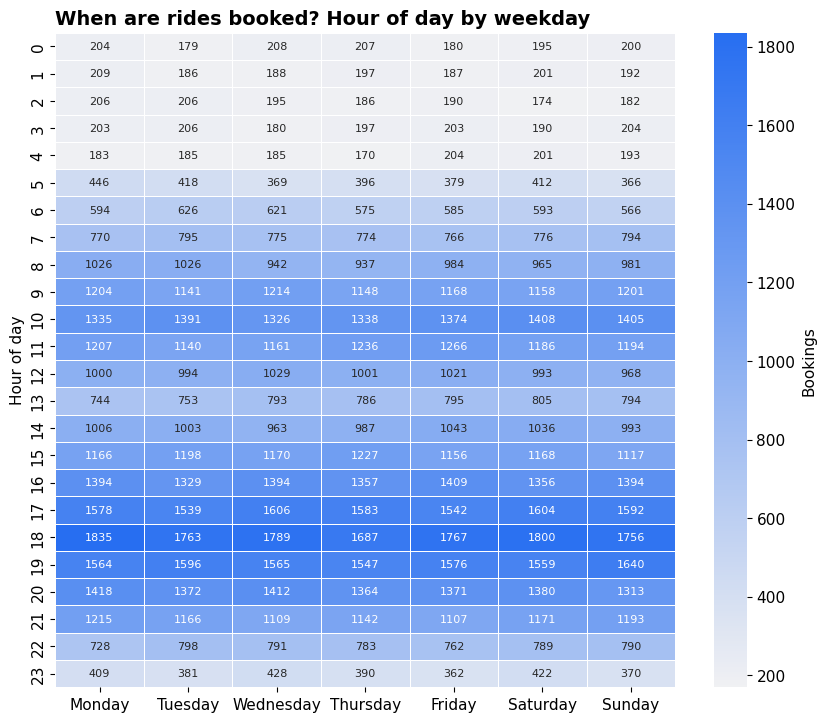

In [44]:
# Chart 04: hour by weekday heatmap
fig, ax = plt.subplots(figsize=(10, 8.5))

sns.heatmap(
    heat,
    cmap=sns.light_palette(BLUE, as_cmap=True),
    annot=True,
    fmt="d",
    annot_kws={"size": 8},
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Bookings"},
    ax=ax,
)

ax.set_title("When are rides booked? Hour of day by weekday")
ax.set_xlabel("")
ax.set_ylabel("Hour of day")
ax.grid(False)

fig.savefig("charts/04_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

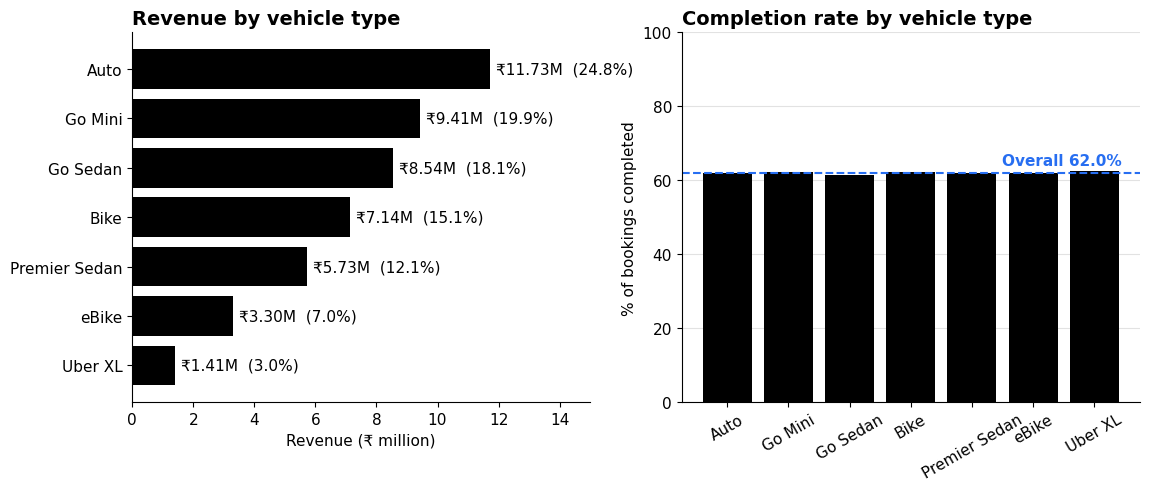

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

rev = vehicle["Revenue"].sort_values()
axes[0].barh(rev.index, rev.values / 1e6, color=BLACK)
for i, (name, value) in enumerate(rev.items()):
    axes[0].text(value / 1e6 + 0.2, i, f"₹{value / 1e6:.2f}M  ({value / rev.sum():.1%})", va="center")
axes[0].set_title("Revenue by vehicle type")
axes[0].set_xlabel("Revenue (₹ million)")
axes[0].set_xlim(0, 15)
axes[0].grid(False)

rate = vehicle["CompletionRate %"]
overall = len(completed) / len(clean) * 100
axes[1].bar(rate.index, rate.values, color=BLACK)
axes[1].axhline(overall, color=BLUE, linestyle="--", linewidth=1.5)
axes[1].text(6.45, overall + 2, f"Overall {overall:.1f}%", color=BLUE, ha="right", fontweight="bold")
axes[1].set_title("Completion rate by vehicle type")
axes[1].set_ylabel("% of bookings completed")
axes[1].set_ylim(0, 100)
axes[1].tick_params(axis="x", rotation=30)

fig.savefig("charts/05_vehicles.png", dpi=200, bbox_inches="tight")
plt.show()

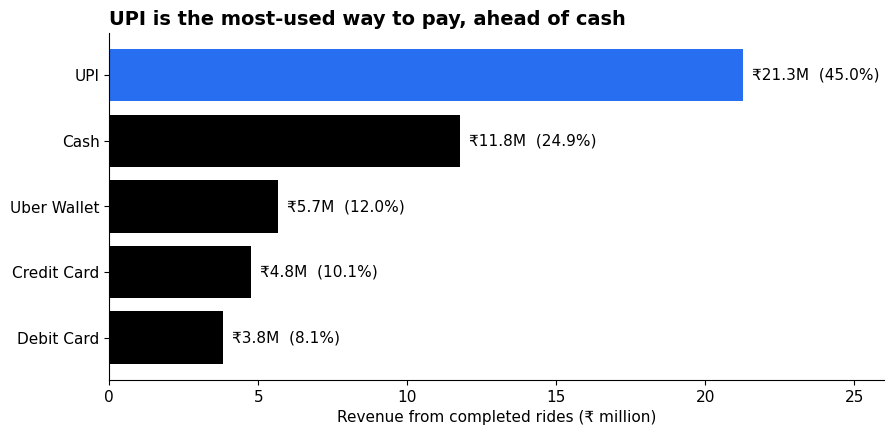

In [46]:
payment_revenue = completed.groupby("Payment Method")["Booking Value"].sum().sort_values()
payment_share = payment_revenue / payment_revenue.sum()

colors = [BLUE if m == payment_revenue.idxmax() else BLACK for m in payment_revenue.index]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(payment_revenue.index, payment_revenue.values / 1e6, color=colors)
for i, (method, value) in enumerate(payment_revenue.items()):
    ax.text(value / 1e6 + 0.3, i, f"₹{value / 1e6:.1f}M  ({payment_share[method]:.1%})", va="center")
ax.set_title("UPI is the most-used way to pay, ahead of cash")
ax.set_xlabel("Revenue from completed rides (₹ million)")
ax.set_xlim(0, 26)
ax.grid(False)

fig.savefig("charts/06_payments.png", dpi=200, bbox_inches="tight")
plt.show()

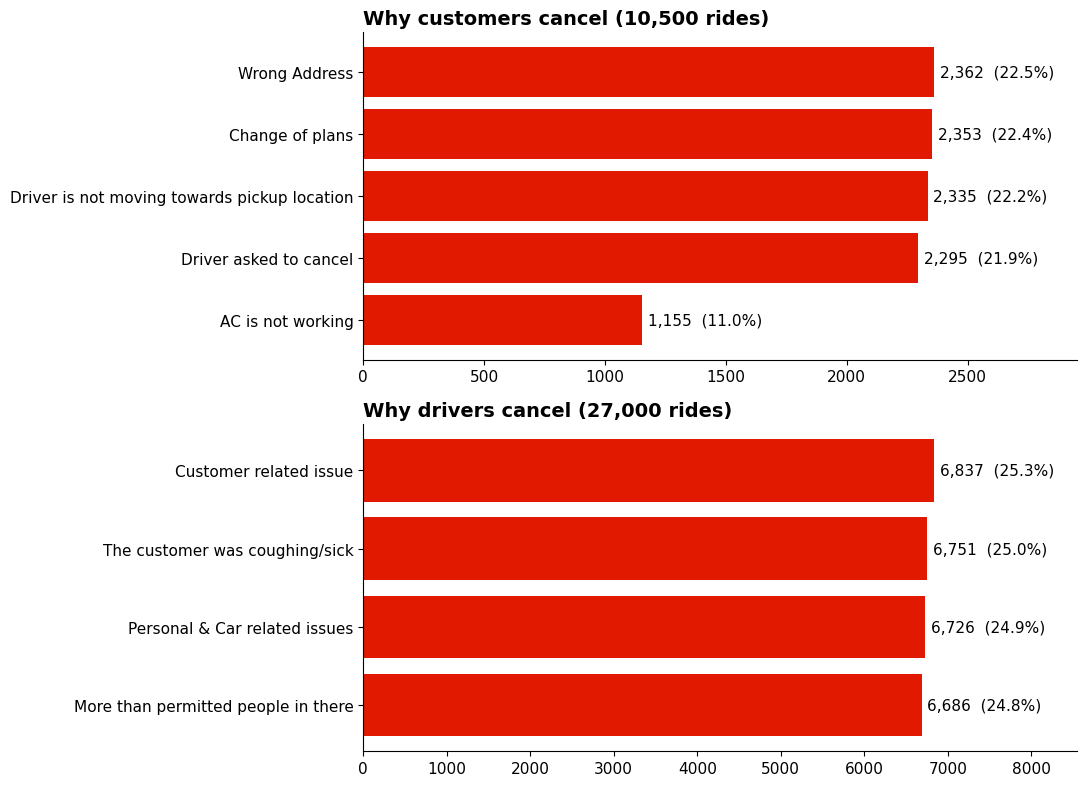

In [47]:
cust = clean["Reason for cancelling by Customer"].value_counts().sort_values()
drv = clean["Driver Cancellation Reason"].value_counts().sort_values()

fig, axes = plt.subplots(2, 1, figsize=(11, 8))

for ax, data, title in [
    (axes[0], cust, "Why customers cancel (10,500 rides)"),
    (axes[1], drv, "Why drivers cancel (27,000 rides)"),
]:
    ax.barh(data.index, data.values, color=RED)
    for i, value in enumerate(data.values):
        ax.text(value + data.max() * 0.01, i, f"{value:,}  ({value / data.sum():.1%})", va="center")
    ax.set_title(title)
    ax.set_xlim(0, data.max() * 1.25)
    ax.grid(False)

fig.tight_layout()
fig.savefig("charts/07_cancellation_reasons.png", dpi=200, bbox_inches="tight")
plt.show()

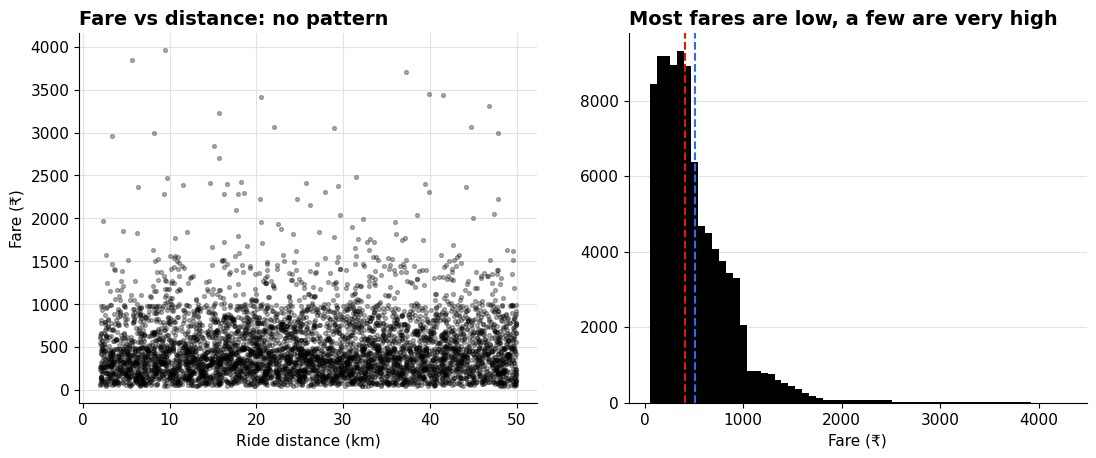

Average fare: ₹508.18 | Median fare: ₹414.00


In [48]:
sample = completed.sample(5000, random_state=42)
mean_fare = completed["Booking Value"].mean()
median_fare = completed["Booking Value"].median()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

axes[0].scatter(sample["Ride Distance"], sample["Booking Value"], s=8, alpha=0.3, color=BLACK)
axes[0].set_title("Fare vs distance: no pattern")
axes[0].set_xlabel("Ride distance (km)")
axes[0].set_ylabel("Fare (₹)")
axes[0].grid(True, axis="both")

axes[1].hist(completed["Booking Value"], bins=60, color=BLACK)
axes[1].axvline(mean_fare, color=BLUE, linestyle="--", linewidth=1.5)
axes[1].axvline(median_fare, color=RED, linestyle="--", linewidth=1.5)
axes[1].set_title("Most fares are low, a few are very high")
axes[1].set_xlabel("Fare (₹)")

fig.savefig("charts/08_fares.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Average fare: ₹{mean_fare:.2f} | Median fare: ₹{median_fare:.2f}")

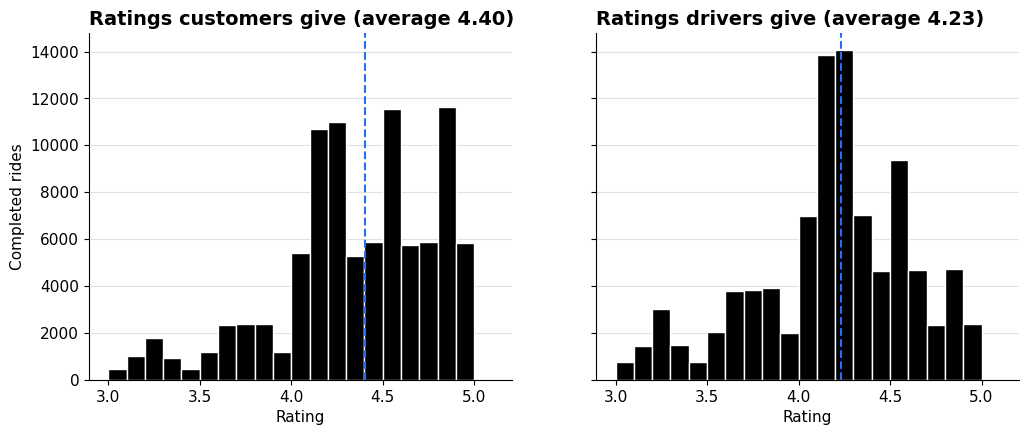

Customer Rating - average: 4.4 | rated 4.5 or higher: 50.0%
Driver Ratings - average: 4.23 | rated 4.5 or higher: 30.2%


In [49]:
bins = np.arange(3.0, 5.15, 0.1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for ax, col, title in [
    (axes[0], "Customer Rating", "Ratings customers give"),
    (axes[1], "Driver Ratings", "Ratings drivers give"),
]:
    ax.hist(completed[col], bins=bins, color=BLACK, edgecolor="white")
    ax.axvline(completed[col].mean(), color=BLUE, linestyle="--", linewidth=1.5)
    ax.set_title(title + f" (average {completed[col].mean():.2f})")
    ax.set_xlabel("Rating")

axes[0].set_ylabel("Completed rides")

fig.savefig("charts/09_ratings.png", dpi=200, bbox_inches="tight")
plt.show()

for col in ["Customer Rating", "Driver Ratings"]:
    print(col, "- average:", round(completed[col].mean(), 2),
          "| rated 4.5 or higher:", f"{(completed[col] >= 4.5).mean():.1%}")

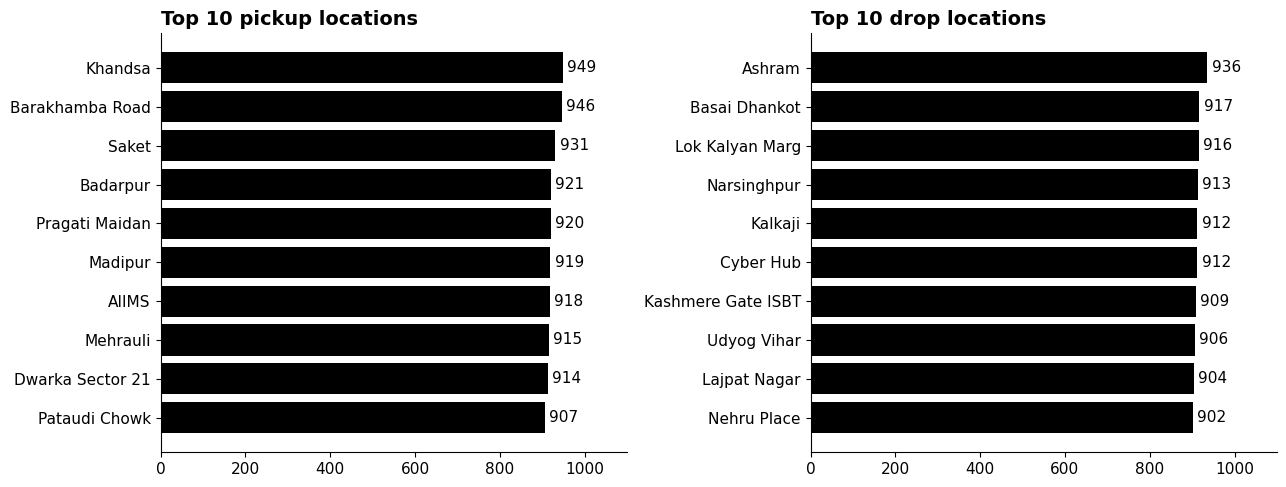

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, col, title in [
    (axes[0], "Pickup Location", "Top 10 pickup locations"),
    (axes[1], "Drop Location", "Top 10 drop locations"),
]:
    top = clean[col].value_counts().head(10).sort_values()
    ax.barh(top.index, top.values, color=BLACK)
    for i, value in enumerate(top.values):
        ax.text(value + 10, i, f"{value:,}", va="center")
    ax.set_title(title)
    ax.set_xlim(0, 1100)
    ax.grid(False)

fig.tight_layout()
fig.savefig("charts/10_locations.png", dpi=200, bbox_inches="tight")
plt.show()

In [51]:
total = len(clean)
unfulfilled = total - len(completed)
avg_fare = completed["Booking Value"].mean()
revenue = clean["CompletedRevenue"].sum()

cust_cancel = clean["IsCancelledByCustomer"].sum()
drv_cancel = clean["IsCancelledByDriver"].sum()
no_driver = clean["IsNoDriverFound"].sum()

revenue_at_risk = (cust_cancel + drv_cancel + no_driver) * avg_fare

hour = clean["Hour"]
hourly = clean.groupby("Hour").size()

cust_reasons = clean["Reason for cancelling by Customer"].value_counts()
driver_behaviour = cust_reasons[["Driver is not moving towards pickup location", "Driver asked to cancel"]].sum()
plans_address = cust_reasons[["Wrong Address", "Change of plans"]].sum()

drv_reasons = clean["Driver Cancellation Reason"].value_counts()
driver_own = drv_reasons["Personal & Car related issues"]

pay = completed.groupby("Payment Method")["Booking Value"].sum()

print(f"Bookings that did not become completed rides: {unfulfilled:,} ({unfulfilled / total:.1%})")
print(f"Driver cancellations as a share of all cancellations: {drv_cancel / (drv_cancel + cust_cancel):.1%}")
print(f"Estimated revenue at risk: ₹{revenue_at_risk:,.0f} ({revenue_at_risk / revenue:.1%} of realised revenue)")
print(f"Share of bookings from 15:00 to 20:59: {hour.between(15, 20).mean():.1%}")
print(f"Busiest hour (18:00) share of all bookings: {(hour == 18).mean():.1%}")
print(f"Busiest hour vs quietest hour: {hourly.max() / hourly.min():.1f}x")
print(f"Customer cancellations caused by driver behaviour: {driver_behaviour:,} ({driver_behaviour / cust_reasons.sum():.1%})")
print(f"Customer cancellations for wrong address or change of plans: {plans_address:,} ({plans_address / cust_reasons.sum():.1%})")
print(f"Driver cancellations that blame the customer or passengers: {1 - driver_own / drv_reasons.sum():.1%}")
print(f"Digital payments share of revenue: {1 - pay['Cash'] / pay.sum():.1%}")

Bookings that did not become completed rides: 57,000 (38.0%)
Driver cancellations as a share of all cancellations: 72.0%
Estimated revenue at risk: ₹24,392,554 (51.6% of realised revenue)
Share of bookings from 15:00 to 20:59: 41.3%
Busiest hour (18:00) share of all bookings: 8.3%
Busiest hour vs quietest hour: 9.4x
Customer cancellations caused by driver behaviour: 4,630 (44.1%)
Customer cancellations for wrong address or change of plans: 4,715 (44.9%)
Driver cancellations that blame the customer or passengers: 75.1%
Digital payments share of revenue: 75.1%


# Key findings

**Headline:** Only 62% of the 150,000 bookings in 2024 became completed rides. The other 57,000 (38%) were lost, and almost half of them (27,000) were cancelled by drivers.

## What the data shows

1. **Completion and cancellation.** 93,000 bookings were completed (62.0%). Drivers cancelled 18.0%, customers 7.0%, 7.0% found no driver, and 6.0% were incomplete. Drivers cancel almost three times as often as customers (72% of all cancellations).
2. **Revenue at risk.** Completed rides earned ₹47.26M (average fare ₹508.18, median ₹414). If each lost booking would have earned the average fare, about ₹24.4M (roughly half of realised revenue) went unearned. This is an estimate, not a measured figure.
3. **Why bookings are cancelled.** 44.1% of customer cancellations cite driver behaviour (driver not moving towards pickup, driver asked to cancel). Another 44.9% are wrong address or change of plans. On the driver side, 75.1% of cancellations cite the customer or passengers. These are the reasons as recorded in the data.
4. **Demand follows the working day.** Bookings peak at 18:00 (12,397, 8.3% of all bookings), about 9.4 times the quietest hour. A second peak sits at 10:00. 41.3% of all bookings fall between 15:00 and 20:59.
5. **Weekday and season do not matter.** Weekly totals sit between 21,215 and 21,644. Bookings per day stay between 407 and 416 in every month, and the February dip is only because the month is shorter.
6. **Vehicles differ in volume, not performance.** Auto earns the most (24.8% of revenue) because it has the most bookings. Completion rate (61.4% to 62.6%), average fare (₹503 to ₹512) and ratings are nearly identical across all seven vehicle types.
7. **Payments.** UPI is 45.0% of revenue and cash 24.9%, so digital methods account for 75.1%.
8. **Fares do not track distance.** The correlation between fare and distance is 0.006. About 3,127 fares are unusually high, up to ₹4,277, so the average fare is pulled above the median.

## Recommendations (ideas to test, not proven causes)

- **Reduce driver cancellations first.** They are the biggest single source of lost bookings (27,000 rides).
- **Reduce wrong-address cancellations** (2,362 rides) with clearer pickup confirmation at booking.
- **Plan driver supply around 16:00 to 20:00**, when demand is highest.

## Data caveats

- Results that are almost identical across vehicles, hours, months and locations are unusual for real ride data, which suggests the dataset is synthetic. Findings describe this dataset, not Uber's real business.
- 1,233 Booking IDs appear twice on different rides. All rows were kept.
- Revenue counts completed rides only. Incomplete rides carry a further ₹4.59M in booking value that is excluded.
- The dataset does not explain what VTAT and CTAT measure, so they are described only by name.

In [52]:
print(sorted(os.listdir("charts")))

['01_booking_outcomes.png', '02_monthly_bookings.png', '03_hourly_demand.png', '04_heatmap.png', '05_vehicles.png', '06_payments.png', '07_cancellation_reasons.png', '08_fares.png', '09_ratings.png', '10_locations.png']


In [53]:
for name in ["clean", "completed", "heat", "vehicle"]:
    print(name, "- OK" if name in globals() else "- MISSING")

for col in ["MonthNum", "Hour", "RideKey", "IsCompleted", "CompletedRevenue"]:
    print(col, "- OK" if col in clean.columns else "- MISSING")

clean - OK
completed - OK
heat - OK
vehicle - OK
MonthNum - OK
Hour - OK
RideKey - OK
IsCompleted - OK
CompletedRevenue - OK


In [54]:
print(sorted(os.listdir("charts")))

['01_booking_outcomes.png', '02_monthly_bookings.png', '03_hourly_demand.png', '04_heatmap.png', '05_vehicles.png', '06_payments.png', '07_cancellation_reasons.png', '08_fares.png', '09_ratings.png', '10_locations.png']


## Adding vehicle pictures for Power BI

In [55]:
import base64
from pathlib import Path

thumb_dir = Path("assets/vehicle_images/thumbs")

file_for = {
    "Auto": "auto.png",
    "Bike": "bike.png",
    "eBike": "ebike.png",
    "Go Mini": "go_mini.png",
    "Go Sedan": "go_sedan.png",
    "Premier Sedan": "premier_sedan.png",
    "Uber XL": "uber_xl.png",
}

def to_data_uri(path):
    encoded = base64.b64encode(path.read_bytes()).decode("ascii")
    return "data:image/png;base64," + encoded

vehicle_dim["ImageURL"] = vehicle_dim["VehicleType"].map(
    lambda v: to_data_uri(thumb_dir / file_for[v])
)

vehicle_dim.assign(Chars=vehicle_dim["ImageURL"].str.len())[["VehicleType", "Chars"]]

,VehicleType,Chars
0,Auto,8478
1,Bike,11866
2,eBike,11530
3,Go Mini,7290
4,Go Sedan,8362
5,Premier Sedan,5882
6,Uber XL,7522


In [56]:
vehicle_dim.to_csv("powerbi_data/dim_vehicle.csv", index=False)
print(pd.read_csv("powerbi_data/dim_vehicle.csv").shape)

(7, 3)
